# Who gains prior use on medication? Participant phenotypes behind the medication effect

`2.26` (Figure 5a) shows that the colour x medication effect on prior use differs widely between
participants. Seven increase, three decrease and ten have intervals that include zero, in both
subtypes. This notebook asks whether a patient phenotype predicts where a participant falls.

**Outcome.** Each participant's medication effect on prior use, $\beta_{\text{col:med}} + u_{i,\text{col:med}}$,
from the reported posterior (`2.26`). The posterior mean is the outcome; the 4,000 draws are used to
carry its uncertainty into the correlations. The three groups are the ones in Figure 5a: interval
above zero ("increase"), below zero ("decrease"), or including zero ("no change").

**Phenotypes.** One value per participant, taken from the OFF session so that nothing on the
predictor side was measured under the treatment whose effect it is meant to predict.

| Family | Variables | Source |
|---|---|---|
| Clinical | age, sex, disease duration, MoCA, Hoehn & Yahr, OFF washout, LEDD, controlled-release levodopa, explicit awareness of the cue | processed metadata; dose table from `2.28` |
| Motor | MDS-UPDRS III total, tremor, bradykinesia and PIGD scores, tremor / bradykinesia ratio, motor response to levodopa | processed metadata |
| Task behaviour | psychometric sensitivity, reward-history and choice-history weights, lapse rate, easy-trial accuracy, median RT | corrected trials, session GLMs |
| DDM | boundary separation, non-decision time, drift gain | leak-1_tc-1 fits, `processed/metadata/ddm_params.csv` (`3.40`) |

Prior use OFF medication is treated separately (Section 3), because a change score is always
negatively correlated with its own baseline.

**Data caveat.** The DDM parameters come from the fits in `processed/`, summarised by `3.40`; P4_ON was
refitted after the 12 Oct raw-data correction, and P3 fails the 60% screen. The GLM-HMM quantity comes from
the `4.20` outputs, which were computed before the correction, when P3_OFF and P4_ON were the same recording,
so P3 and P4 are masked in it. Every other quantity is computed here from the corrected trials.

**Outputs** go to the gitignored `outputs/` directory. Nothing is written to the data directory.

| File | Contents |
|---|---|
| `medication_response_participants.csv` | one row per participant: effect, group and every phenotype |
| `medication_response_baseline.csv` | regression-to-the-mean and reliability checks |
| `medication_response_screen.csv` | phenotype screen: Spearman rho, bootstrap CI, permutation p, FDR q |
| `medication_response_moderators.csv` | hierarchical-model moderator tests |
| `medication_response_profiles.csv` | phenotype medians by response group |
| `medication_response_baseline.pdf/.png`, `medication_response_screen.pdf/.png`, `medication_response_tremor.pdf/.png` | figures |

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *
import json
from statsmodels.stats.multitest import multipletests

from src.data_io import catalog
from src.utils.mcmc_cache import FIT_SETTINGS, TERMS, build_design, cached_draws, ess_bulk, prepare_trials, rhat

In [2]:
metadata = catalog.load_metadata()
trials = catalog.load_trials()
effects = catalog.load("participant_medication_effects").set_index("participant_id")
effect_draws_npz = catalog.read(catalog.output_path("participant_medication_effects_draws.npz"))
dose = catalog.read(catalog.output_path("medication_dose_table.csv")).set_index("participant")

# DDM: the leak-1_tc-1 fits as summarised by 3.40 (P4_ON refitted on the corrected data).
ddm_params = catalog.load("metadata_ddm_params")
# GLM-HMM: 4.20's occupancy-weighted prior effect, computed before the 12 Oct correction, when P3_OFF and
# P4_ON were one recording, so those two patients are masked.
HMM_MASK = ("P3_", "P4_")
hmm_sessions = catalog.read(catalog.output_path("glm_hmm_heldout_occupancy_weighted.csv"))

SUBTYPE_COLOR = {"tremor": "#2a78d6", "bradykinetic": "#eb6834"}   # reference palette slots 1-2
SUBTYPE_LABEL = {"tremor": "Tremor dominant", "bradykinetic": "Bradykinesia dominant"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
GROUP_ORDER = ["increase", "no change", "decrease"]
rng = np.random.default_rng(0)
print(f"{len(effects)} participants with a medication effect from 2.26")

20 participants with a medication effect from 2.26


## 1. Session-level measures from the corrected trials

One logistic regression per session, `choice ~ coherence + colour + previous rewarded choice +
previous choice`, the session-level analogue of the reported model. Its colour weight is the
session's prior use in log-odds. Its coherence weight is psychometric sensitivity, and the two
history weights index reliance on reward and choice history. The model-free prior effect is the
proportion of prior-side choices at 0% coherence on positive-prior minus equal-prior colour trials,
as in `2.28`. Odd and even trials are fitted separately for split-half reliability.

In [3]:
def session_measures(trial_data):
    t = trial_data[trial_data["medication"].isin(["off", "on"])].copy()
    t["signed_choice"] = t["choice"] * 2 - 1
    t["rewarded_choice"] = t["signed_choice"] * np.where(t["outcome"] == 1, 1, -1)
    by_session = t.groupby("session_id")
    t["prev_rc"] = by_session["rewarded_choice"].shift()
    t["prev_c"] = by_session["signed_choice"].shift()
    t["coh"] = t["signed_coherence"] / 100
    t["col"] = np.where(t["color"] == 1, 0.5, -0.5)
    t["trial"] = by_session.cumcount()

    rows = []
    for session, s in t.groupby("session_id"):
        d = s.dropna(subset=["prev_rc"])
        fit = sm.Logit(d["choice"], sm.add_constant(d[["coh", "col", "prev_rc", "prev_c"]])).fit(disp=0)
        zero = s[s["coherence"] == 0]
        halves = {}
        for name, half in [("odd", s[s["trial"] % 2 == 1]), ("even", s[s["trial"] % 2 == 0])]:
            halves[name] = sm.Logit(half["choice"], sm.add_constant(half[["coh", "col"]])).fit(disp=0).params["col"]
        rows.append({
            "session_id": session,
            "prior_use": fit.params["col"],
            "prior_use_mf": zero.loc[zero["color"] == 1, "choice"].mean() - zero.loc[zero["color"] == 0, "choice"].mean(),
            "prior_use_odd": halves["odd"], "prior_use_even": halves["even"],
            "sensitivity": fit.params["coh"],
            "reward_history": fit.params["prev_rc"],
            "choice_history": fit.params["prev_c"],
            "bias": fit.params["const"],
            "easy_accuracy": s.loc[s["coherence"] == 100, "outcome"].mean(),
            "median_rt": s["reaction_time"].median(),
        })
    return pd.DataFrame(rows).set_index("session_id")


behaviour = session_measures(trials)
behaviour.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
prior_use,80.0,0.210,0.636,-1.316,-0.233,0.168,0.536,1.989
prior_use_mf,80.0,0.044,0.156,-0.266,-0.058,0.032,0.123,0.504
prior_use_odd,80.0,0.192,0.687,-1.448,-0.261,0.217,0.566,1.960
prior_use_even,80.0,0.197,0.620,-1.148,-0.126,0.076,0.507,1.806
sensitivity,80.0,3.530,2.144,0.172,2.297,3.178,4.203,12.747
reward_history,80.0,0.249,0.280,-0.482,0.107,0.225,0.371,1.331
choice_history,80.0,0.038,0.330,-0.759,-0.175,0.036,0.287,0.721
bias,80.0,0.055,0.347,-0.622,-0.196,0.022,0.267,1.133
easy_accuracy,80.0,0.917,0.093,0.604,0.905,0.949,0.976,1.000
median_rt,80.0,884.514,180.731,612.094,779.154,849.106,938.809,1681.495


In [4]:
ddm = ddm_params.set_index("session_id")
ddm_sessions = pd.DataFrame(index=ddm.index)
for p in ["a", "ndt", "drift_gain", "z", "drift_offset"]:
    ddm_sessions[f"ddm_{p}"] = (ddm[f"{p}_prior_cond_1"] + ddm[f"{p}_prior_cond_0"]) / 2           # mean of both colours
    ddm_sessions[f"ddm_{p}_prior"] = ddm[f"{p}_prior_cond_1"] - ddm[f"{p}_prior_cond_0"]          # positive minus equal
hmm = hmm_sessions.set_index("session_id")[["published"]].rename(columns={"published": "hmm_prior_use"})
hmm.loc[hmm.index.str.startswith(HMM_MASK)] = np.nan
print(f"DDM sessions: {ddm_sessions['ddm_a'].notna().sum()}, GLM-HMM sessions: {hmm['hmm_prior_use'].notna().sum()} (P3, P4 masked)")

DDM sessions: 98, GLM-HMM sessions: 96 (P3, P4 masked)


## 2. Participant table

Per-session variables are pivoted to OFF and ON columns, with `_chg` = ON minus OFF. Phenotypes use the
OFF value. Hoehn & Yahr is the highest stage recorded in either session, because some patients have it
in only one. LEDD is derivable for 7 of the 20 patients, as documented in `2.28`.

In [5]:
pd_sessions = metadata[metadata["is_pd"] != 0].assign(med=lambda d: d["treatment"].str.lower()).set_index("session_id")
sessions = pd_sessions.join(behaviour).join(ddm_sessions).join(hmm)
sessions = sessions.rename(columns={"tremor_score": "tremor", "bradykinesia_score": "brady", "pigd_score": "pigd",
                                    "overall_psych_lapse": "lapse", "explicitness": "explicit"})

SESSION_VARS = (["UPDRS", "tremor", "brady", "pigd", "trem_by_brady", "explicit", "lapse"] + list(behaviour.columns)
                + list(ddm_sessions.columns) + ["hmm_prior_use"])
wide = sessions.reset_index().pivot(index="subject_id", columns="med", values=SESSION_VARS)
wide.columns = [f"{var}_{med}" for var, med in wide.columns]
for var in SESSION_VARS:
    wide[f"{var}_chg"] = wide[f"{var}_on"] - wide[f"{var}_off"]

off = sessions[sessions["med"] == "off"].set_index("subject_id")
participants = pd.DataFrame({
    "subtype": effects["subtype"],
    "effect": effects["mean"], "effect_low": effects["2.5%"], "effect_high": effects["97.5%"],
    "group": effects["interval"].map({"above 0": "increase", "below 0": "decrease", "includes 0": "no change"}),
})
participants = participants.join(pd.DataFrame({
    "age": off["age"], "male": (off["gender"] == "M").astype(float),
    "years_since_diagnosis": off["years_since_diagnosis"],
    "MoCA": sessions.groupby("subject_id")["MoCA"].mean(),
    "hoehn_yahr": sessions.groupby("subject_id")["Hoehn_and_Yahr_Stage"].max(),
    "washout_h": off["off_meds_hrs"],
    "off_first": off["off_med_first"], "site": off["experiment_site"],
    "UPDRS_improvement": off["UPDRS_improvement"], "tremor_improvement": off["tremor_improvement"],
    "bradykinesia_improvement": off["bradykinesia_improvement"],
    "pd_meds": off["pd_meds"],
})).join(wide)
participants["LEDD"] = dose["LEDD (mg/day)"]
participants["controlled_release"] = dose["formulation"].str.contains("CR").astype(float)
participants["no_levodopa"] = (dose["formulation"] == "no levodopa").astype(float)
participants["subtype_td"] = (participants["subtype"] == "tremor").astype(float)
participants["log_median_rt_off"] = np.log(participants["median_rt_off"])

draws = {}
for subtype in ["tremor", "bradykinetic"]:
    for j, pid in enumerate(effect_draws_npz[f"{subtype}_participant_ids"]):
        draws[pid] = effect_draws_npz[f"{subtype}_draws"][:, j]
participants = participants.sort_values("effect")
effect_draws = np.column_stack([draws[p] for p in participants.index])    # (4000, participant)

check = np.corrcoef(participants["effect"], participants["prior_use_chg"])[0, 1]
print(f"session-GLM prior-use change vs 2.26 effect: r = {check:.3f}")
pd.crosstab(participants["group"], participants["subtype"]).loc[GROUP_ORDER]

session-GLM prior-use change vs 2.26 effect: r = 0.985


subtype,bradykinetic,tremor
group,,
increase,3,4
no change,5,5
decrease,2,1


## 3. Is low prior use OFF medication a phenotype?

The patients who increased most had the lowest prior use OFF medication, and the three who decreased
had among the highest. Read naively, that is a baseline-dependent drug effect, the inverted-U account
of dopamine. But a change score shares its baseline's noise, so ON minus OFF correlates negatively
with OFF even when medication does nothing. The question is whether the relationship is larger than
that.

Three checks:

1. **OFF versus ON.** If prior use were a stable trait, a participant's two sessions would correlate.
2. **Oldham's test.** Correlate the change with the participant's *average* of OFF and ON rather than
   with OFF. That removes the shared-noise artefact; a negative correlation remains only if ON is less
   variable than OFF, i.e. if medication pulls participants together.
3. **The model's own estimate.** In the reported posterior, the correlation across participants
   between their average prior use (`col`) and their medication effect (`col:med`).

Split-half reliability within a session shows whether each session's value is precise enough for the
first check to mean anything.

In [6]:
rows = []
for label, var in [("session GLM, log-odds", "prior_use"), ("model-free, 0% coherence", "prior_use_mf")]:
    for subset_name, block in [("all 20", participants)] + [(s, g) for s, g in participants.groupby("subtype")]:
        x_off, x_on = block[f"{var}_off"].to_numpy(), block[f"{var}_on"].to_numpy()
        change, average = x_on - x_off, (x_on + x_off) / 2
        r_pair, p_pair = stats.pearsonr(x_off, x_on)
        r_old, p_old = stats.pearsonr(change, average)
        rows.append({"measure": label, "participants": subset_name, "n": len(block),
                     "r(OFF, ON)": r_pair, "p": p_pair,
                     "r(change, OFF)": stats.pearsonr(change, x_off)[0],
                     "Oldham r(change, average)": r_old, "Oldham p": p_old,
                     "SD OFF": x_off.std(ddof=1), "SD ON": x_on.std(ddof=1)})
baseline = pd.DataFrame(rows)
baseline.round(3)

,measure,participants,n,"r(OFF, ON)",p,"r(change, OFF)","Oldham r(change, average)",Oldham p,SD OFF,SD ON
0,"session GLM, log-odds",all 20,20,-0.164,0.490,-0.777,-0.052,0.828,0.617,0.586
1,"session GLM, log-odds",bradykinetic,10,-0.016,0.965,-0.719,-0.018,0.960,0.548,0.538
2,"session GLM, log-odds",tremor,10,-0.222,0.538,-0.823,-0.176,0.628,0.703,0.591
3,"model-free, 0% coherence",all 20,20,-0.074,0.758,-0.794,-0.203,0.391,0.166,0.136
4,"model-free, 0% coherence",bradykinetic,10,-0.076,0.834,-0.736,-0.007,0.985,0.152,0.151
5,"model-free, 0% coherence",tremor,10,0.031,0.932,-0.845,-0.444,0.199,0.183,0.113


In [7]:
COL, COL_MED = TERMS.index("col"), TERMS.index("col:med")
rows = []
for subtype in ["tremor", "bradykinetic"]:
    a = cached_draws(subtype)
    beta = a["beta"].reshape(-1, len(TERMS))
    sd = a["sd_u"].reshape(-1, len(TERMS))
    z = a["z_u"].reshape(-1, a["z_u"].shape[2], len(TERMS))
    mean_use = beta[:, [COL]] + z[:, :, COL] * sd[:, [COL]]
    med_effect = beta[:, [COL_MED]] + z[:, :, COL_MED] * sd[:, [COL_MED]]
    off_use = mean_use - med_effect / 2
    for label, x in [("average prior use (Oldham)", mean_use), ("OFF prior use", off_use)]:
        r = np.array([np.corrcoef(x[k], med_effect[k])[0, 1] for k in range(len(x))])
        rows.append({"subtype": subtype, "correlate of col:med": label, "posterior median r": np.median(r),
                     "2.5%": np.percentile(r, 2.5), "97.5%": np.percentile(r, 97.5)})
model_baseline = pd.DataFrame(rows)
model_baseline.round(2)

,subtype,correlate of col:med,posterior median r,2.5%,97.5%
0,tremor,average prior use (Oldham),-0.15,-0.47,0.18
1,tremor,OFF prior use,-0.82,-0.91,-0.67
2,bradykinetic,average prior use (Oldham),-0.10,-0.43,0.24
3,bradykinetic,OFF prior use,-0.75,-0.88,-0.55


In [8]:
spearman_brown = lambda r: 2 * r / (1 + r)
rel_rows = []
all_sessions = behaviour.join(metadata.set_index("session_id")["is_pd"])
for label, block in [("PD sessions", all_sessions[all_sessions["is_pd"] != 0]),
                     ("sessions of the 20 subtyped patients", all_sessions.loc[all_sessions.index.str.split("_").str[0].isin(participants.index)])]:
    r = stats.pearsonr(block["prior_use_odd"], block["prior_use_even"])[0]
    rel_rows.append({"reliability": "within session (odd vs even trials)", "sample": label, "n": len(block),
                     "r": r, "Spearman-Brown": spearman_brown(r)})
pd_wide = all_sessions[all_sessions["is_pd"] != 0].join(pd_sessions["med"]).join(pd_sessions["subject_id"]).pivot(
    index="subject_id", columns="med", values="prior_use")
rel_rows.append({"reliability": "across sessions (OFF vs ON)", "sample": "all PD patients", "n": len(pd_wide),
                 "r": stats.pearsonr(pd_wide["off"], pd_wide["on"])[0], "Spearman-Brown": np.nan})
rel_rows.append({"reliability": "across sessions (OFF vs ON)", "sample": "20 subtyped patients", "n": len(participants),
                 "r": stats.pearsonr(participants["prior_use_off"], participants["prior_use_on"])[0], "Spearman-Brown": np.nan})
reliability = pd.DataFrame(rel_rows)
reliability.round(3)

,reliability,sample,n,r,Spearman-Brown
0,within session (odd vs even trials),PD sessions,80,0.773,0.872
1,within session (odd vs even trials),sessions of the 20 subtyped patients,40,0.739,0.850
2,across sessions (OFF vs ON),all PD patients,40,-0.131,NaN
3,across sessions (OFF vs ON),20 subtyped patients,20,-0.164,NaN


saved medication_response_baseline.pdf, medication_response_baseline.png


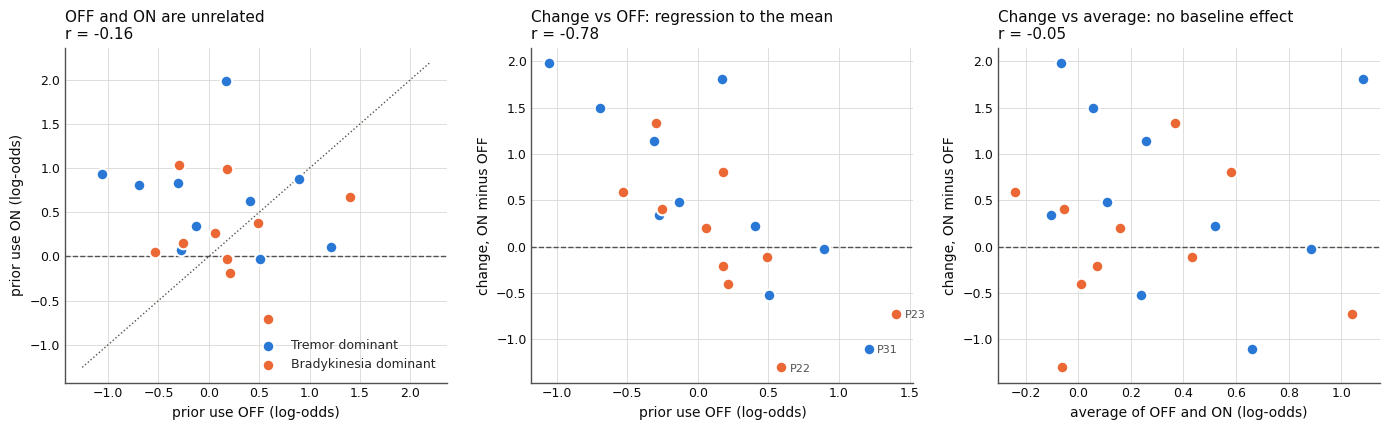

In [9]:
def style(ax):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelcolor=INK, labelsize=9)
    ax.grid(color=GRID, lw=0.6, zorder=0)
    ax.set_axisbelow(True)


def scatter_by_subtype(ax, x, y, block):
    for subtype in ["tremor", "bradykinetic"]:
        g = block[block["subtype"] == subtype]
        ax.scatter(x.loc[g.index], y.loc[g.index], s=70, color=SUBTYPE_COLOR[subtype], edgecolor="white",
                   linewidth=1.5, zorder=3, label=SUBTYPE_LABEL[subtype])


p = participants
x_off, x_on = p["prior_use_off"], p["prior_use_on"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
panels = [
    (x_off, x_on, "prior use OFF (log-odds)", "prior use ON (log-odds)", "OFF and ON are unrelated"),
    (x_off, x_on - x_off, "prior use OFF (log-odds)", "change, ON minus OFF", "Change vs OFF: regression to the mean"),
    ((x_off + x_on) / 2, x_on - x_off, "average of OFF and ON (log-odds)", "change, ON minus OFF", "Change vs average: no baseline effect"),
]
for ax, (x, y, xl, yl, title) in zip(axes, panels):
    style(ax)
    scatter_by_subtype(ax, x, y, p)
    r = stats.pearsonr(x, y)[0]
    ax.axhline(0, color=MUTED, lw=1, ls="--", zorder=1)
    ax.set_xlabel(xl, color=INK, fontsize=10)
    ax.set_ylabel(yl, color=INK, fontsize=10)
    ax.set_title(f"{title}\nr = {r:+.2f}", fontsize=11, color=INK, loc="left")
lims = [min(x_off.min(), x_on.min()) - 0.2, max(x_off.max(), x_on.max()) + 0.2]
axes[0].plot(lims, lims, color=MUTED, lw=1, ls=":", zorder=1)
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
for pid in ["P22", "P31", "P23"]:
    axes[1].annotate(pid, (x_off[pid], (x_on - x_off)[pid]), xytext=(6, -3), textcoords="offset points", fontsize=8, color=MUTED)
fig.tight_layout()
catalog.save_figure(fig, "medication_response_baseline")
plt.show()

## 4. Phenotype screen

Spearman correlation of each phenotype with the participant's medication effect. For each:

- a percentile bootstrap 95% interval over participants (5,000 resamples);
- a two-sided permutation p-value (10,000 permutations);
- the 95% range of rho across the posterior draws of the effects, which shows how much the
  estimation uncertainty in each participant's effect moves the correlation;
- Benjamini-Hochberg q within the family and across all phenotypes.

With 20 participants a correlation needs |rho| of about 0.45 to reach p < 0.05, so this screen can
only find large effects.

In [10]:
PHENOTYPES = {
    "Clinical": {
        "age": "Age", "male": "Male sex", "years_since_diagnosis": "Years since diagnosis", "MoCA": "MoCA",
        "hoehn_yahr": "Hoehn & Yahr stage", "washout_h": "OFF washout (h)", "LEDD": "LEDD (mg/day)",
        "controlled_release": "Controlled-release levodopa", "explicit_off": "Explicit awareness, OFF",
    },
    "Motor, MDS-UPDRS III OFF": {
        "UPDRS_off": "Total score", "tremor_off": "Tremor score", "brady_off": "Bradykinesia score",
        "pigd_off": "PIGD score", "trem_by_brady_off": "Tremor / bradykinesia ratio",
        "UPDRS_improvement": "Motor response to levodopa (%)", "tremor_improvement": "Tremor response (%)",
        "bradykinesia_improvement": "Bradykinesia response (%)",
    },
    "Task behaviour OFF": {
        "sensitivity_off": "Sensitivity (coherence weight)", "reward_history_off": "Reward-history weight",
        "choice_history_off": "Choice-history weight", "lapse_off": "Lapse rate", "easy_accuracy_off": "Easy-trial accuracy",
        "median_rt_off": "Median RT",
    },
    "DDM OFF": {"ddm_a_off": "Boundary separation", "ddm_ndt_off": "Non-decision time", "ddm_drift_gain_off": "Drift gain"},
}


def spearman_stats(x, y, y_draws, n_boot=5000, n_perm=10000):
    ok = ~np.isnan(x)
    x, y, y_draws = x[ok], y[ok], y_draws[:, ok]
    rho = stats.spearmanr(x, y)[0]
    boot = []
    for _ in range(n_boot):
        i = rng.integers(0, len(x), len(x))
        if np.ptp(x[i]) > 0:
            boot.append(stats.spearmanr(x[i], y[i])[0])
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    perm = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(n_perm)])
    post = np.array([stats.spearmanr(x, y_draws[k])[0] for k in range(0, len(y_draws), 10)])
    return {"n": int(ok.sum()), "rho": rho, "boot 2.5%": np.nanpercentile(boot, 2.5), "boot 97.5%": np.nanpercentile(boot, 97.5),
            "p (perm)": (np.abs(perm) >= abs(rho) - 1e-12).mean(),
            "rho over posterior 2.5%": np.percentile(post, 2.5), "rho over posterior 97.5%": np.percentile(post, 97.5)}


rows = []
y = participants["effect"].to_numpy()
for family, variables in PHENOTYPES.items():
    for var, label in variables.items():
        rows.append({"family": family, "phenotype": label, "variable": var,
                     **spearman_stats(participants[var].astype(float).to_numpy(), y, effect_draws)})
screen = pd.DataFrame(rows)
screen["q (family)"] = screen.groupby("family")["p (perm)"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
screen["q (all)"] = multipletests(screen["p (perm)"], method="fdr_bh")[1]
screen.sort_values("p (perm)").round(3)

,family,phenotype,variable,n,rho,boot 2.5%,boot 97.5%,p (perm),rho over posterior 2.5%,rho over posterior 97.5%,q (family),q (all)
10,"Motor, MDS-UPDRS III OFF",Tremor score,tremor_off,20,0.566,0.149,0.850,0.011,0.360,0.633,0.089,0.289
22,Task behaviour OFF,Median RT,median_rt_off,20,-0.468,-0.751,-0.027,0.040,-0.573,-0.277,0.241,0.523
12,"Motor, MDS-UPDRS III OFF",PIGD score,pigd_off,20,0.385,-0.018,0.693,0.094,0.181,0.501,0.373,0.791
9,"Motor, MDS-UPDRS III OFF",Total score,UPDRS_off,20,0.343,-0.099,0.695,0.140,0.141,0.440,0.373,0.791
17,Task behaviour OFF,Sensitivity (coherence weight),sensitivity_off,20,0.311,-0.187,0.702,0.175,0.128,0.420,0.526,0.791
21,Task behaviour OFF,Easy-trial accuracy,easy_accuracy_off,20,0.240,-0.274,0.652,0.299,0.053,0.353,0.598,0.791
24,DDM OFF,Non-decision time,ddm_ndt_off,20,-0.242,-0.632,0.251,0.301,-0.417,-0.071,0.904,0.791
11,"Motor, MDS-UPDRS III OFF",Bradykinesia score,brady_off,20,0.238,-0.244,0.708,0.313,0.074,0.352,0.604,0.791
6,Clinical,LEDD (mg/day),LEDD,7,0.414,-0.737,1.000,0.364,0.144,0.775,0.753,0.791
2,Clinical,Years since diagnosis,years_since_diagnosis,20,0.207,-0.240,0.549,0.387,0.071,0.383,0.753,0.791


saved medication_response_screen.pdf, medication_response_screen.png


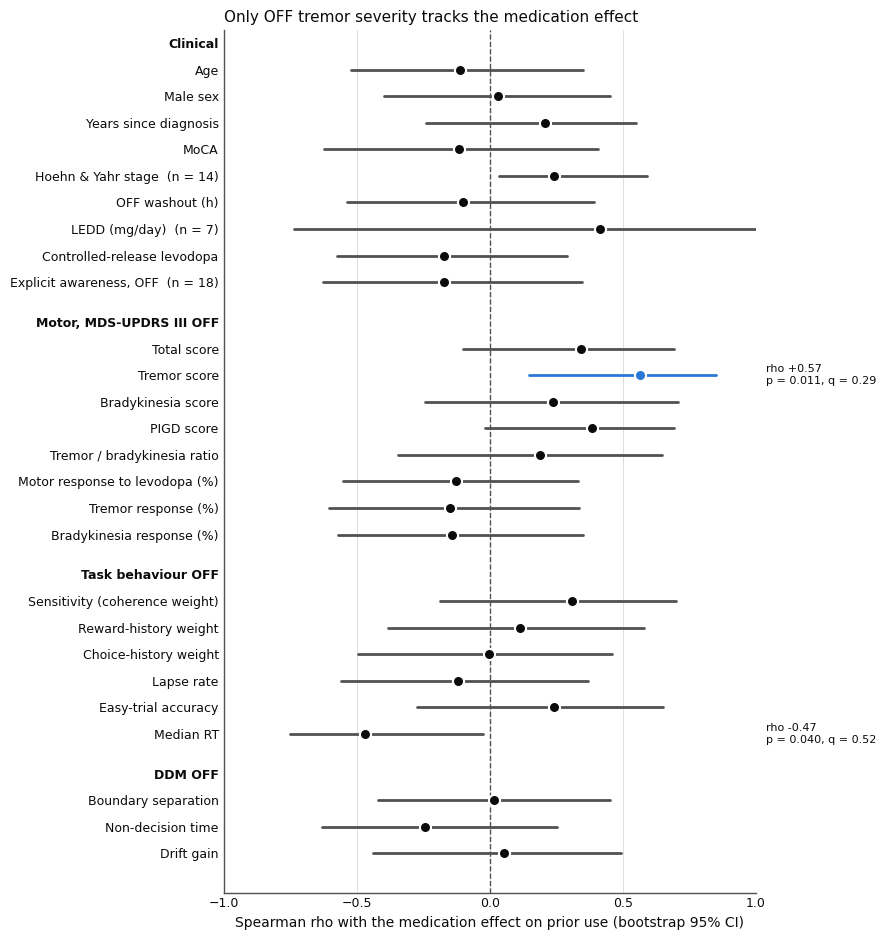

In [11]:
fig, ax = plt.subplots(figsize=(9, 9.5))
style(ax)
ax.grid(axis="y", visible=False)
ypos, labels, headings, y0 = [], [], [], 0
for family, block in screen.groupby("family", sort=False):
    ypos.append(y0); labels.append(family); headings.append(len(labels) - 1)
    y0 += 1
    for _, row in block.iterrows():
        highlight = row["variable"] == "tremor_off"
        color = SUBTYPE_COLOR["tremor"] if highlight else MUTED
        ax.plot([row["boot 2.5%"], row["boot 97.5%"]], [y0, y0], color=color, lw=2, solid_capstyle="round", zorder=2)
        ax.scatter(row["rho"], y0, s=64, color=color if highlight else INK, edgecolor="white", linewidth=1.5, zorder=3)
        ypos.append(y0)
        labels.append(row["phenotype"] + (f"  (n = {row['n']})" if row["n"] < len(participants) else ""))
        if row["p (perm)"] < 0.05:
            ax.text(1.04, y0, f"rho {row['rho']:+.2f}\np = {row['p (perm)']:.3f}, q = {row['q (all)']:.2f}",
                    fontsize=8, color=INK, va="center", clip_on=False)
        y0 += 1
    y0 += 0.5
ax.axvline(0, color=MUTED, lw=1, ls="--", zorder=1)
ax.set_yticks(ypos)
ax.set_yticklabels(labels, fontsize=9, color=INK)
for k in headings:
    ax.get_yticklabels()[k].set_fontweight("bold")
ax.tick_params(axis="y", length=0)
ax.invert_yaxis()
ax.set_xlim(-1, 1)
ax.set_xticks([-1, -0.5, 0, 0.5, 1])
ax.set_xlabel("Spearman rho with the medication effect on prior use (bootstrap 95% CI)", color=INK, fontsize=10)
ax.set_title("Only OFF tremor severity tracks the medication effect", fontsize=11, color=INK, loc="left")
fig.tight_layout()
catalog.save_figure(fig, "medication_response_screen")
plt.show()

## 5. Tremor severity

The one phenotype that stands out in the screen. Three robustness checks on the correlation, then the
test that matters: tremor score entered as a moderator of `col:med` inside the reported hierarchical
model, so the trial-level uncertainty is carried properly.

**Robustness.** The correlation within each subtype separately, its range when each participant is
left out in turn, and a regression adjusting for subtype (tremor score partly defines subtype).

In [12]:
rows = []
for var in ["tremor_off", "pigd_off", "brady_off", "UPDRS_off", "log_median_rt_off"]:
    rho_all = stats.spearmanr(participants[var], participants["effect"])[0]
    loo = [stats.spearmanr(participants.drop(i)[var], participants.drop(i)["effect"])[0] for i in participants.index]
    z = participants.assign(score=(participants[var] - participants[var].mean()) / participants[var].std())
    ols = smf.ols("effect ~ score + subtype_td", data=z).fit()
    rows.append({
        "phenotype": var, "rho, all 20": rho_all,
        **{f"rho within {s}": stats.spearmanr(g[var], g["effect"])[0] for s, g in participants.groupby("subtype")},
        "LOO min": min(loo), "LOO max": max(loo),
        "subtype-adjusted slope per SD": ols.params["score"], "slope p": ols.pvalues["score"],
        "rho with OFF prior use": stats.spearmanr(participants[var], participants["prior_use_off"])[0],
        "rho with ON prior use": stats.spearmanr(participants[var], participants["prior_use_on"])[0],
    })
tremor_robustness = pd.DataFrame(rows).set_index("phenotype")
tremor_robustness.round(2)

,"rho, all 20",rho within bradykinetic,rho within tremor,LOO min,LOO max,subtype-adjusted slope per SD,slope p,rho with OFF prior use,rho with ON prior use
phenotype,,,,,,,,,
tremor_off,0.57,0.45,0.59,0.50,0.68,0.45,0.09,-0.47,0.20
pigd_off,0.38,0.41,0.47,0.31,0.45,0.29,0.09,-0.13,0.61
brady_off,0.24,0.07,0.78,0.14,0.37,0.28,0.13,-0.34,0.03
UPDRS_off,0.34,0.02,0.75,0.26,0.46,0.21,0.22,-0.37,0.11
log_median_rt_off,-0.47,-0.47,-0.60,-0.55,-0.40,-0.30,0.08,0.61,-0.18


**Hierarchical moderator models.** The reported model (`mcmc_cache.sample_model`) fitted to all 20
patients together, plus a standardised participant-level phenotype entered as a main effect and with
its colour, medication and colour x medication interactions:

$$\eta = X(\beta + u_i) + s_i(\gamma_0 + \gamma_1\,\text{col} + \gamma_2\,\text{med} + \gamma_3\,\text{col}\cdot\text{med})$$

$\gamma_3$ is the change in the medication effect on prior use per standard deviation of the
phenotype. The between-participant SD of `col:med` with and without the moderator shows how much
heterogeneity the phenotype explains. Same priors and sampler settings as the reported fits.

Each fit takes about five minutes. Results are cached under `outputs/medication_response_moderators/`
with the standardised phenotype values they were fitted to, and are refitted if those change. The cached fits in this run were sampled in parallel outside the notebook, by the same model code with the same seed and settings, and loaded into this cache.

In [13]:
MODERATOR_FITS = ["none", "tremor_off", "brady_off", "pigd_off", "UPDRS_off", "UPDRS_improvement", "age",
                  "years_since_diagnosis", "log_median_rt_off", "tremor_off+subtype_td", "tremor_off+pigd_off"]


def standardised(names):
    return {n: ((participants[n] - participants[n].mean()) / participants[n].std(ddof=1)).to_dict() for n in names}


def signature(names):
    """What a cached fit was sampled on, to 6 decimals."""
    return {n: {k: round(v, 6) for k, v in values.items()} for n, values in standardised(names).items()}


def fit_moderators(names, subset):
    import pymc as pm

    design, outcomes, subject_index, subjects = build_design(subset)
    col, med = subset["col"].to_numpy(), subset["med"].to_numpy()
    columns, terms = [], []
    for n, values in standardised(names).items():
        s = subset["subject_id"].map(values).to_numpy()
        columns += [s, s * col, s * med, s * col * med]
        terms += [n, f"{n}:col", f"{n}:med", f"{n}:col:med"]
    with pm.Model():
        beta = pm.Normal("beta", 0, 2.5, shape=design.shape[1])
        gamma = pm.Normal("gamma", 0, 2.5, shape=len(columns)) if columns else None
        sd_u = pm.HalfNormal("sd_u", 1.0, shape=design.shape[1])
        z_u = pm.Normal("z_u", 0, 1, shape=(len(subjects), design.shape[1]))
        eta = pm.math.sum(design * (beta + (z_u * sd_u)[subject_index]), axis=1)
        if columns:
            eta = eta + pm.math.dot(np.column_stack(columns), gamma)
        pm.Bernoulli("obs", logit_p=eta, observed=outcomes)
        idata = pm.sample(FIT_SETTINGS["draws"], tune=FIT_SETTINGS["tune"], chains=FIT_SETTINGS["chains"],
                          cores=FIT_SETTINGS["chains"], target_accept=FIT_SETTINGS["target_accept"],
                          random_seed=FIT_SETTINGS["seed"], progressbar=False)
    b, sd = idata.posterior["beta"].values, idata.posterior["sd_u"].values
    out = {"fit": "+".join(names) or "none", "settings": FIT_SETTINGS, "scores": signature(names),
           "col:med mean": float(b[..., COL_MED].mean()), "sd_u col:med": float(sd[..., COL_MED].mean()),
           "sd_u col:med 2.5%": float(np.percentile(sd[..., COL_MED], 2.5)),
           "sd_u col:med 97.5%": float(np.percentile(sd[..., COL_MED], 97.5)),
           "divergences": int(idata.sample_stats["diverging"].values.sum())}
    if columns:
        g = idata.posterior["gamma"].values
        for n in names:
            d = g[..., terms.index(f"{n}:col:med")]
            out[n] = {"mean": float(d.mean()), "2.5%": float(np.percentile(d, 2.5)), "97.5%": float(np.percentile(d, 97.5)),
                      "P(> 0)": float((d > 0).mean()), "r_hat": float(rhat(d)), "ess_bulk": float(ess_bulk(d))}
    out["max r_hat (population)"] = float(max(rhat(b[..., i]) for i in range(b.shape[-1])))
    return out


subset = prepare_trials(trials, list(participants.index))
moderator_fits = {}
for spec in MODERATOR_FITS:
    names = [] if spec == "none" else spec.split("+")
    file = catalog.output_path(f"medication_response_moderators/{spec}.json")
    cached = catalog.read(file) if file.exists() else None
    if cached and cached["settings"] == FIT_SETTINGS and cached["scores"] == signature(names):
        moderator_fits[spec] = cached
        continue
    print(f"{spec}: sampling")
    moderator_fits[spec] = fit_moderators(names, subset)
    catalog.write(moderator_fits[spec], file)

reference_sd = moderator_fits["none"]["sd_u col:med"]
rows = []
for spec, fit in moderator_fits.items():
    for n in ([] if spec == "none" else spec.split("+")):
        rows.append({"fit": spec, "moderator": n, **{k: fit[n][k] for k in ["mean", "2.5%", "97.5%", "P(> 0)", "r_hat", "ess_bulk"]},
                     "sd_u col:med": fit["sd_u col:med"],
                     "heterogeneity explained": 1 - (fit["sd_u col:med"] / reference_sd) ** 2,
                     "divergences": fit["divergences"]})
moderators = pd.DataFrame(rows)
print(f"reference fit, no moderator: col:med {moderator_fits['none']['col:med mean']:+.3f}, "
      f"between-participant SD {reference_sd:.3f} [{moderator_fits['none']['sd_u col:med 2.5%']:.2f}, {moderator_fits['none']['sd_u col:med 97.5%']:.2f}]")
moderators.round(3)

reference fit, no moderator: col:med +0.309, between-participant SD 0.829 [0.57, 1.18]


,fit,moderator,mean,2.5%,97.5%,P(> 0),r_hat,ess_bulk,sd_u col:med,heterogeneity explained,divergences
0,tremor_off,tremor_off,0.387,0.033,0.758,0.983,1.003,1158.550,0.746,0.189,0
1,brady_off,brady_off,0.174,-0.252,0.577,0.808,1.001,1623.868,0.836,-0.017,0
2,pigd_off,pigd_off,0.329,-0.055,0.701,0.960,1.004,1441.423,0.785,0.103,0
3,UPDRS_off,UPDRS_off,0.213,-0.193,0.605,0.868,1.003,1617.890,0.832,-0.008,0
4,UPDRS_improvement,UPDRS_improvement,-0.090,-0.511,0.320,0.334,1.001,1647.568,0.854,-0.061,0
5,age,age,-0.084,-0.508,0.327,0.345,1.002,1740.833,0.859,-0.074,0
6,years_since_diagnosis,years_since_diagnosis,0.190,-0.230,0.606,0.828,1.003,1404.921,0.834,-0.014,0
7,log_median_rt_off,log_median_rt_off,-0.301,-0.692,0.093,0.058,1.003,1556.630,0.794,0.081,0
8,tremor_off+subtype_td,tremor_off,0.510,-0.082,1.086,0.956,1.001,NaN,0.767,0.143,0
9,tremor_off+subtype_td,subtype_td,-0.165,-0.781,0.416,0.274,1.001,NaN,0.767,0.143,0


saved medication_response_tremor.pdf, medication_response_tremor.png


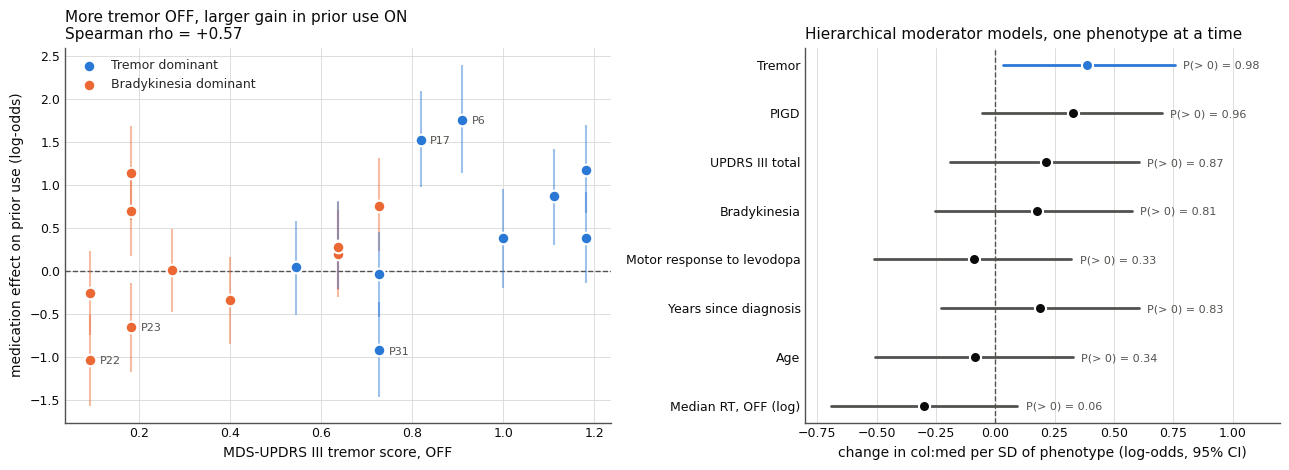

In [14]:
LABELS = {"tremor_off": "Tremor", "brady_off": "Bradykinesia", "pigd_off": "PIGD", "UPDRS_off": "UPDRS III total",
          "UPDRS_improvement": "Motor response to levodopa", "age": "Age", "years_since_diagnosis": "Years since diagnosis",
          "log_median_rt_off": "Median RT, OFF (log)", "subtype_td": "Subtype (TD vs BD)"}
single = moderators[moderators["fit"] == moderators["moderator"]].set_index("moderator")
order = ["tremor_off", "pigd_off", "UPDRS_off", "brady_off", "UPDRS_improvement", "years_since_diagnosis", "age", "log_median_rt_off"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
style(ax)
p = participants
for subtype, g in p.groupby("subtype"):
    ax.errorbar(g["tremor_off"], g["effect"], yerr=[g["effect"] - g["effect_low"], g["effect_high"] - g["effect"]],
                ls="", color=SUBTYPE_COLOR[subtype], alpha=0.45, lw=1.5, zorder=2)
scatter_by_subtype(ax, p["tremor_off"], p["effect"], p)
ax.axhline(0, color=MUTED, lw=1, ls="--", zorder=1)
for pid in ["P31", "P22", "P23", "P6", "P17"]:
    ax.annotate(pid, (p.loc[pid, "tremor_off"], p.loc[pid, "effect"]), xytext=(7, -3), textcoords="offset points", fontsize=8, color=MUTED)
rho = stats.spearmanr(p["tremor_off"], p["effect"])[0]
ax.set_xlabel("MDS-UPDRS III tremor score, OFF", color=INK, fontsize=10)
ax.set_ylabel("medication effect on prior use (log-odds)", color=INK, fontsize=10)
ax.set_title(f"More tremor OFF, larger gain in prior use ON\nSpearman rho = {rho:+.2f}", fontsize=11, color=INK, loc="left")
ax.legend(frameon=False, fontsize=9, loc="upper left")

ax = axes[1]
style(ax)
ax.grid(axis="y", visible=False)
for i, n in enumerate(order):
    row = single.loc[n]
    color = SUBTYPE_COLOR["tremor"] if n == "tremor_off" else MUTED
    ax.plot([row["2.5%"], row["97.5%"]], [i, i], color=color, lw=2, solid_capstyle="round", zorder=2)
    ax.scatter(row["mean"], i, s=64, color=color if n == "tremor_off" else INK, edgecolor="white", linewidth=1.5, zorder=3)
    ax.annotate(f"P(> 0) = {row['P(> 0)']:.2f}", (max(row["97.5%"], 0), i), xytext=(6, -3), textcoords="offset points", fontsize=8, color=MUTED)
ax.axvline(0, color=MUTED, lw=1, ls="--", zorder=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([LABELS[n] for n in order], color=INK, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-0.8, 1.2)
ax.set_xlabel("change in col:med per SD of phenotype (log-odds, 95% CI)", color=INK, fontsize=10)
ax.set_title("Hierarchical moderator models, one phenotype at a time", fontsize=11, color=INK, loc="left")
fig.tight_layout()
catalog.save_figure(fig, "medication_response_tremor")
plt.show()

## 6. What the three groups look like

Medians by Figure 5a group, with a Kruskal-Wallis test. The decrease group has three participants, so
the tests are descriptive. The three decreasers are listed individually afterwards.

In [15]:
PROFILE = {"age": "Age", "years_since_diagnosis": "Years since diagnosis", "MoCA": "MoCA", "washout_h": "OFF washout (h)",
           "UPDRS_off": "UPDRS III OFF", "UPDRS_improvement": "Motor response to levodopa (%)", "tremor_off": "Tremor OFF",
           "brady_off": "Bradykinesia OFF", "pigd_off": "PIGD OFF", "sensitivity_off": "Sensitivity OFF",
           "reward_history_off": "Reward-history weight OFF", "median_rt_off": "Median RT OFF (ms)", "lapse_off": "Lapse OFF",
           "ddm_a_off": "DDM boundary OFF", "ddm_ndt_off": "DDM non-decision time OFF", "ddm_drift_gain_off": "DDM drift gain OFF",
           "explicit_off": "Explicit awareness OFF", "explicit_on": "Explicit awareness ON",
           "prior_use_off": "Prior use OFF", "prior_use_on": "Prior use ON"}
rows = []
for var, label in PROFILE.items():
    groups = [participants.loc[participants["group"] == g, var].dropna() for g in GROUP_ORDER]
    rows.append({"phenotype": label, **{g: x.median() for g, x in zip(GROUP_ORDER, groups)},
                 "Kruskal-Wallis p": stats.kruskal(*groups)[1]})
profiles = pd.DataFrame(rows).set_index("phenotype")
counts = participants.groupby("group").agg(n=("effect", "size"), tremor_dominant=("subtype_td", "sum"), male=("male", "sum"),
                                           OFF_first=("off_first", "sum"), Harvard=("site", lambda s: (s == "Harvard").sum())).loc[GROUP_ORDER]
display(counts)
profiles.round(2)

,n,tremor_dominant,male,OFF_first,Harvard
group,,,,,
increase,7,4.0,6.0,4.0,2
no change,10,5.0,6.0,4.0,3
decrease,3,1.0,3.0,2.0,1


,increase,no change,decrease,Kruskal-Wallis p
phenotype,,,,
Age,64.00,61.50,62.00,0.89
Years since diagnosis,5.00,3.00,1.00,0.49
MoCA,27.00,27.00,29.00,0.46
OFF washout (h),17.70,15.42,20.50,0.29
UPDRS III OFF,22.00,18.00,22.00,0.71
Motor response to levodopa (%),5.56,31.01,36.36,0.38
Tremor OFF,0.82,0.64,0.18,0.26
Bradykinesia OFF,0.88,0.60,0.94,0.59
PIGD OFF,0.40,0.20,0.40,0.32


In [16]:
decreasers = participants.loc[participants["group"] == "decrease",
    ["subtype", "effect", "age", "years_since_diagnosis", "MoCA", "UPDRS_off", "UPDRS_on", "UPDRS_improvement",
     "tremor_off", "brady_off", "washout_h", "prior_use_off", "prior_use_on", "pd_meds"]]
decreasers.round(2)

,subtype,effect,age,years_since_diagnosis,MoCA,UPDRS_off,UPDRS_on,UPDRS_improvement,tremor_off,brady_off,washout_h,prior_use_off,prior_use_on,pd_meds
participant_id,,,,,,,,,,,,,,
P22,bradykinetic,-1.04,62.0,1.00,29.0,22.0,14.0,36.36,0.09,0.94,24.0,0.59,-0.71,\trasagiline (Azilect) 1 mg TABS; Neupro 3 MG/...
P31,tremor,-0.92,57.0,0.75,27.0,12.0,10.0,16.67,0.73,0.12,18.5,1.21,0.11,carbidopa-levodopa (SINEMET) 25-100 mg per tab...
P23,bradykinetic,-0.65,65.0,5.00,29.0,28.0,14.0,50.00,0.18,1.19,20.5,1.40,0.68,carbidopa-levodopa (Sinemet) 25-100 mg tablet


## 7. Where the change shows up

Not a phenotype question, but it says what kind of change the groups differ in. Spearman correlation of
the medication effect with each model's own ON-minus-OFF change. `4.20` already showed that the mixed
model, the GLM-HMM and the DDM drift offset agree about individuals; this table adds the DDM starting
point and the non-prior parameters, to see whether anything else moves with prior use.

In [17]:
CHANGES = {"hmm_prior_use_chg": "GLM-HMM occupancy-weighted prior effect", "ddm_drift_offset_prior_chg": "DDM drift-offset prior effect",
           "ddm_z_prior_chg": "DDM starting-point prior effect", "ddm_a_chg": "DDM boundary", "ddm_ndt_chg": "DDM non-decision time",
           "ddm_drift_gain_chg": "DDM drift gain", "sensitivity_chg": "Sensitivity", "reward_history_chg": "Reward-history weight",
           "choice_history_chg": "Choice-history weight", "bias_chg": "Overall side bias", "lapse_chg": "Lapse rate",
           "easy_accuracy_chg": "Easy-trial accuracy", "median_rt_chg": "Median RT", "UPDRS_chg": "UPDRS III",
           "tremor_chg": "Tremor score", "brady_chg": "Bradykinesia score"}
rows = []
for var, label in CHANGES.items():
    x = participants[var].astype(float).to_numpy()
    ok = ~np.isnan(x)
    rho, p = stats.spearmanr(x[ok], participants["effect"].to_numpy()[ok])
    rows.append({"ON minus OFF change in": label, "n": int(ok.sum()), "rho": rho, "p": p})
changes = pd.DataFrame(rows).set_index("ON minus OFF change in")
changes.round(3)

,n,rho,p
ON minus OFF change in,,,
GLM-HMM occupancy-weighted prior effect,19,0.972,0.000
DDM drift-offset prior effect,20,0.860,0.000
DDM starting-point prior effect,20,-0.263,0.262
DDM boundary,20,-0.248,0.292
DDM non-decision time,20,0.120,0.613
DDM drift gain,20,0.162,0.494
Sensitivity,20,0.039,0.870
Reward-history weight,20,-0.402,0.079
Choice-history weight,20,-0.080,0.738


## Results and interpretation

Values are from this run. The outcome is the `2.26` posterior, so they are stable across reruns.

### Short answer

No clinical, demographic, dosing or OFF-state task phenotype separates the participants whose prior use
rises on medication from those whose prior use falls, with one partial exception: **tremor severity
OFF medication**. It explains about a fifth of the between-participant spread, and the evidence for it is
suggestive rather than confirmatory. The most striking group difference, prior use in the OFF session,
is regression to the mean and not a phenotype.

### 1. Low prior use OFF does not predict improvement

The increase group had low prior use OFF (median -0.31 log-odds) and the decrease group high (median
+1.21). That pattern is what a change score produces on its own:

| Check | Value |
|---|---|
| Correlation of a participant's OFF and ON prior use, 20 subtyped patients | r = -0.16 |
| Same, all 40 PD patients | r = -0.13 |
| Change vs OFF prior use | r = -0.78 |
| Change vs the average of OFF and ON (Oldham) | r = -0.05, p = 0.83 |
| SD of prior use, OFF vs ON | 0.62 vs 0.59 |
| Reported posterior: participant average prior use vs col:med, TD / BD | -0.15 [-0.47, 0.18] / -0.10 [-0.43, 0.24] |
| Within-session split-half reliability (Spearman-Brown) | 0.85 |

Prior use is measured precisely within a session, but one session's level says nothing about the other
session's. Medication does not pull participants toward a common level: ON is as spread out as OFF. So
there is no evidence for a baseline-dependent (inverted-U) drug effect in these data, and OFF prior use
cannot be used to predict who responds.

This also constrains any explanation. Because the two sessions are uncorrelated, most of what Figure 5a
shows is a difference between two visits, and a stable trait can only account for the part of that
difference it predicts.

### 2. The phenotype screen finds tremor and little else

Of 26 phenotypes, two reach uncorrected p < 0.05 and none survives correction across all of them:

| Phenotype | rho [bootstrap 95% CI] | p | q (family) | q (all) |
|---|---|---|---|---|
| Tremor score, OFF | +0.57 [0.15, 0.85] | 0.011 | 0.09 | 0.29 |
| Median RT, OFF | -0.47 [-0.75, -0.03] | 0.040 | 0.24 | 0.52 |

Median RT OFF is measured in the same session as OFF prior use and correlates with it (rho = +0.61), so it
most likely inherits the regression-to-the-mean effect above rather than marking a trait.

Null, with |rho| at most 0.34 and p at least 0.14: age, sex, disease duration, MoCA, Hoehn & Yahr, OFF
washout, controlled-release formulation, motor response to levodopa (total, tremor or bradykinesia),
total UPDRS III, bradykinesia score, tremor / bradykinesia ratio, psychometric sensitivity, reward- and
choice-history weights, lapse rate, easy-trial accuracy, and the DDM boundary, non-decision time and drift
gain. LEDD is larger (rho = +0.41) but is derivable for only 7 patients, and its interval runs from -0.74
to +1.

### 3. Tremor severity: consistent, but modest and not confirmatory

- **Not just the subtype label.** The correlation is positive within each subtype (TD +0.59, BD +0.45)
  and stays between +0.50 and +0.68 when any one participant is left out.
- **In the hierarchical model,** tremor OFF moderates col:med by +0.39 log-odds per SD [0.03, 0.76],
  P(> 0) = 0.98, and lowers the between-participant SD of the medication effect from 0.83 to 0.75, about
  19% of the variance.
- **Tremor rather than subtype.** With both in the model, tremor keeps its size (+0.51 [-0.08, 1.09]) and
  subtype adds nothing (-0.17 [-0.78, 0.42]). The continuous score carries what the TD / BD split
  captures.
- **PIGD points the same way** (+0.33 [-0.06, 0.70], P(> 0) = 0.96). With tremor in the same model, the
  two together account for about 27% of the variance.
- **How it works.** High-tremor patients have low prior use OFF (rho = -0.47) but not ON (rho = +0.20).
  The tremor-linked deficit is present OFF and absent ON. Tremor is scored on a separate instrument, so
  this is not a regression-to-the-mean artefact.

Caveats: eight phenotypes were tested as moderators, and P(> 0) = 0.98 for one of eight does not survive
a multiplicity correction. The SD intervals with and without tremor overlap almost entirely. The
direction is consistent with the paper's TD-PD result, which makes it a plausible graded version of that
finding rather than an independent discovery.

### 4. The three decreasers have nothing clinical in common

P22 (BD, diagnosed 1 year earlier, the only patient on no levodopa: rasagiline plus rotigotine), P31
(TD, 0.75 years, the mildest motor score at UPDRS III 12) and P23 (BD, 5 years, the largest motor
improvement at 50%). None of the clinical or OFF-state group comparisons reaches p < 0.15. The one exception is
explicit awareness of the cue in the ON session (p = 0.05): all three decreasers were rated explicit ON,
against a median of 0 in the other groups. Awareness was rated per session, and the session notes show
some of those explicit beliefs were inaccurate. It reads better as a strategy difference within that
visit than as a trait.

### 5. What the change consists of

The medication effect tracks the change in DDM drift offset (rho = +0.86) and in the GLM-HMM
occupancy-weighted prior effect (rho = +0.97), as `4.20` reported. It does not track the starting-point
prior effect (-0.26), or the boundary, non-decision time and drift gain (|rho| below 0.3). Responders
change how the cue biases evidence accumulation, not where accumulation starts. The change in motor
scores is unrelated (|rho| at most 0.17): the cognitive and motor responses to medication do not go
together in these patients. The change in reward-history weight leans the opposite way (rho = -0.40,
p = 0.08), a weak hint that more cue-based prior use comes with less reliance on reward history.

### Reporting

- Report tremor severity as an exploratory moderator, with its interval and the multiplicity caveat. Do
  not call it a predictor of response.
- Do not present OFF prior use as a determinant of who responds. Report the Oldham result if a reviewer
  raises baseline dependence.
- The DDM parameters come from the fits in `processed/` (P4_ON refitted on the corrected data). The
  GLM-HMM quantity still comes from `4.20`'s pre-correction outputs with P3 and P4 masked; rerun `4.20` on
  the refitted bundles before quoting it.

## Save

In [18]:
keep = [c for c in participants.columns if c != "pd_meds"]
catalog.save_table(participants[keep].rename_axis("participant_id"), "medication_response_participants.csv")
catalog.save_table(pd.concat([baseline.assign(check="observed sessions"),
                              model_baseline.assign(check="reported posterior"),
                              reliability.assign(check="reliability")], ignore_index=True), "medication_response_baseline.csv", index=False)
catalog.save_table(screen, "medication_response_screen.csv", index=False)
catalog.save_table(moderators, "medication_response_moderators.csv", index=False)
catalog.save_table(profiles, "medication_response_profiles.csv")

saved medication_response_participants.csv
saved medication_response_baseline.csv
saved medication_response_screen.csv
saved medication_response_moderators.csv
saved medication_response_profiles.csv
